## Node2Vec:

---

In [3]:
import pickle

with open('../../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [11]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

Computing transition probabilities:   0%|          | 0/150 [00:00<?, ?it/s]

Computing transition probabilities: 100%|██████████| 150/150 [00:00<00:00, 187.56it/s]


In [12]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4,
)

In [13]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [14]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [15]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [16]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [17]:
display(vectors_64d)


array([[-0.18043269, -0.32802454,  0.25184795, ..., -0.20376511,
         0.21341114,  0.02985105],
       [ 0.26653504, -0.024436  ,  0.39118296, ..., -0.43750206,
         0.0947528 , -0.1439473 ],
       [-0.13190433, -0.36141166,  0.21655734, ..., -0.1252973 ,
         0.12584558,  0.02283766],
       ...,
       [ 0.21187247,  0.02242379,  0.50615394, ..., -0.4929996 ,
         0.11037976, -0.0397421 ],
       [-0.14112774, -0.11086494,  0.31128272, ..., -0.28778338,
         0.26450932, -0.04689521],
       [ 0.19046281,  0.02803549,  0.40304068, ..., -0.50115013,
         0.032591  , -0.06220247]], dtype=float32)

In [19]:
# Loading the pyshcological profile labels:

node_labels = np.load('../../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [20]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [21]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


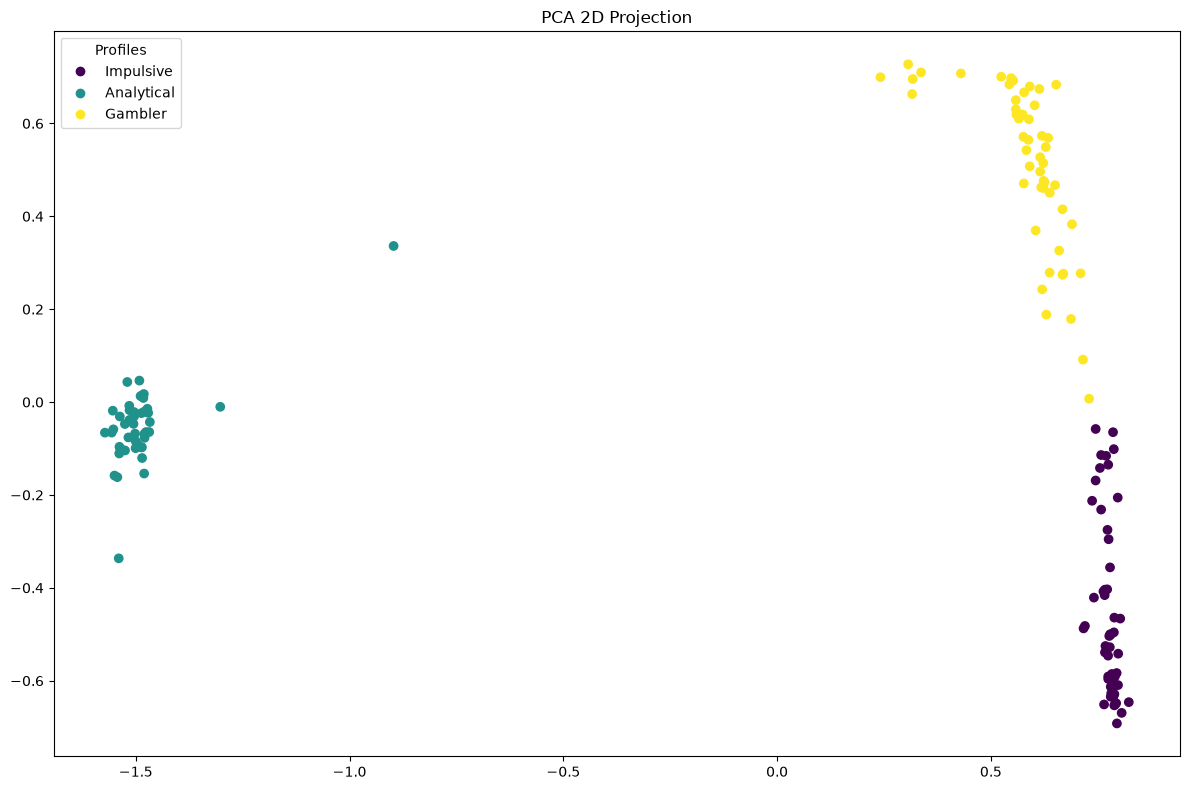

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')
plt.title('PCA 2D Projection')

plt.tight_layout()
plt.savefig('PCA-Projection.png', dpi=300)
plt.show()

---

### t-SNE:

In [14]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    max_iter=1000, 
    random_state=42
)

In [15]:
vectors_tsne = tsne.fit_transform(vectors_64d)

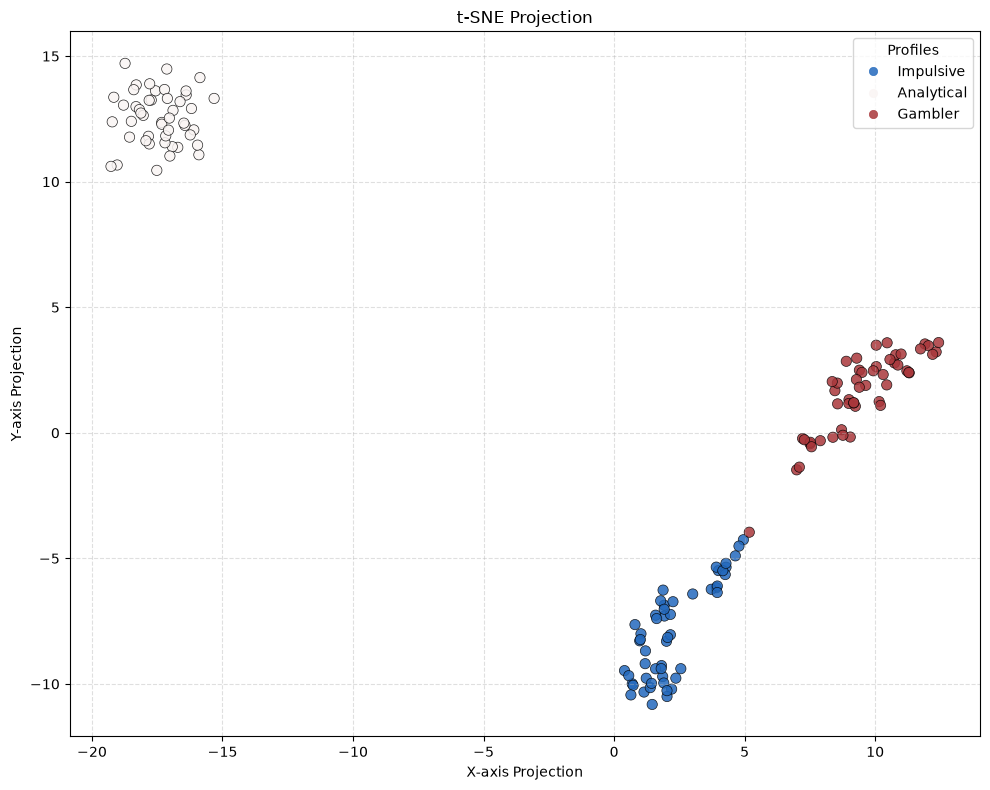

In [23]:
import seaborn as sns

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    vectors_tsne[:, 0], 
    vectors_tsne[:, 1], 
    c=node_labels, 
    cmap='vlag',  
    alpha=0.85, 
    s=55, 
    edgecolors='k',
    linewidth=0.5
)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')

plt.grid(True, linestyle='--', alpha=0.4)

plt.xlabel('X-axis Projection')
plt.ylabel('Y-axis Projection')
plt.title('t-SNE Projection')

plt.tight_layout()
plt.show()